In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import chi2, median_abs_deviation
from IPython.display import display
from itertools import combinations
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.linear_model import LinearRegression
from scipy.optimize import minimize_scalar

# Лабораторная работа 3
Выполнили Шакина Анна, Воробьев Андрей

# Задание 1

**Датасет Possum Regression.** Одна строка - одно животное. Оценим среднюю длину головы `hdlngth` (мм) по общей длине `totlngth` (см). Используем только полные пары измерений. [Описание датасета](https://www.kaggle.com/datasets/abrambeyer/openintro-possum)

In [2]:
animals = pd.read_csv("data/possum.csv")
pairs = animals.dropna(subset=["totlngth", "hdlngth"])
x = pairs.totlngth.to_numpy()
y = pairs.hdlngth.to_numpy()
X = np.column_stack([np.ones(len(x)), x])
print(f"Полных пар: {len(x)} из {len(animals)}")
display(pairs[["case", "totlngth", "hdlngth"]].head())

,case,totlngth,hdlngth
0,1,89.0,94.1
1,2,91.5,92.5
2,3,95.5,94.0
3,4,92.0,93.2
4,5,85.5,91.5


Полных пар: 104 из 104


## Классические оценки параметров
В модели $y_i=\beta_0+\beta_1 x_i+\varepsilon_i$ предполагаем $E(\varepsilon_i\mid x_i)=0$. Метод наименьших квадратов (МНК) минимизирует сумму квадратов остатков. Отсюда получаем нормальные уравнения $X^\top X\hat\beta=X^\top y$. Наклон измеряется в мм/см. Свободный член соответствует длине тела 0 см, за пределами выборки.

In [3]:
ols = np.linalg.lstsq(X, y, rcond=None)[0]
print(f"МНК: длина головы = {ols[0]:.3f} + {ols[1]:.3f} * общая длина")

МНК: длина головы = 42.710 + 0.573 * общая длина


## Робастные оценки
### Обобщённая M-оценка (GM-оценка)
Минимизируем $\sum_i w_i\rho_c(u_i)$, где $u_i=(y_i-x_i^\top\beta)/s$, а $x_i^\top$ здесь обозначает строку матрицы плана со свободным членом. Функция потерь Губера равна $u^2/2$ при $|u|\le c$ и $c|u|-c^2/2$ за этим порогом. Её производная $\psi_c(u)$ ограничена по модулю числом $c=1.345$.

Масштаб $s$ фиксируем по остаткам прямой МНК. Для этого берём медианное абсолютное отклонение (MAD) остатков от их медианы и делим на $0{,}67449$ - медиану модуля стандартной нормальной величины. Для защиты от крайних значений признака берём $w_i=\min(1,1.96/d_i)$, где $d_i$ - расстояние от медианы общей длины в единицах нормированного медианного абсолютного отклонения. Уравнение оценки $\sum_i w_i x_i\psi_c(u_i)=0$ решаем последовательными шагами взвешенного МНК.

In [4]:
k = 1.345
scale = median_abs_deviation(y - X @ ols, scale="normal")
distance = abs(x - np.median(x)) / median_abs_deviation(x, scale="normal")
w = 1.96 / np.maximum(1.96, distance)
gm = ols.copy()
for iteration in range(100):
    u = (y - X @ gm) / scale
    weight = w * k / np.maximum(k, abs(u))
    root = np.sqrt(weight)
    updated = np.linalg.lstsq(root[:, None]*X, root*y, rcond=None)[0]
    change = np.max(abs(updated - gm))
    gm = updated
    if change < 1e-9:
        break
else:
    raise RuntimeError("Итерации не сошлись")
display(pd.DataFrame({"МНК": ols, "GM-оценка": gm}, index=["Свободный член", "Наклон, мм/см"]))
print(f"Робастный наклон отличается от МНК на {gm[1]-ols[1]:+.3f} мм/см.")

,МНК,GM-оценка
Свободный член,42.709793,44.65511
"Наклон, мм/см",0.572901,0.54905


Робастный наклон отличается от МНК на -0.024 мм/см.


## Функции потерь
Сравним вклад одного стандартизованного остатка при весах наблюдения 1 и 0,5, затем посмотрим на обе прямые в исходных единицах.

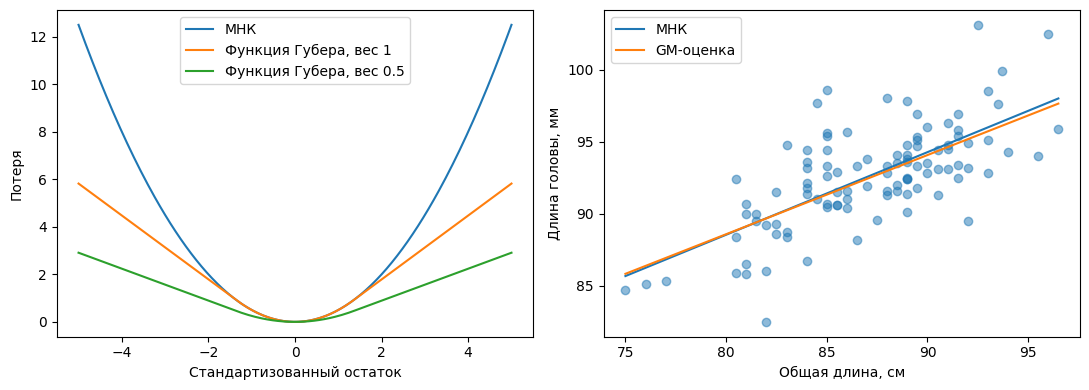

За порогом Губера: 26 животных. Вес по длине уменьшен у 3.


In [5]:
u = np.linspace(-5, 5, 251)
huber = np.where(abs(u) <= k, u**2/2, k*abs(u)-k**2/2)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for loss, label in [(u**2/2, "МНК"), (huber, "Функция Губера, вес 1"), (0.5*huber, "Функция Губера, вес 0.5")]:
    ax[0].plot(u, loss, label=label)
ax[0].set(xlabel="Стандартизованный остаток", ylabel="Потеря")
ax[1].scatter(x, y, alpha=0.5)
grid = np.array([x.min(), x.max()])
for b, label in [(ols, "МНК"), (gm, "GM-оценка")]:
    ax[1].plot(grid, b[0]+b[1]*grid, label=label)
ax[1].set(xlabel="Общая длина, см", ylabel="Длина головы, мм")
for axis in ax:
    axis.legend()
plt.tight_layout()
plt.show()
print(f"За порогом Губера: {sum(abs(y-X@gm)>k*scale)} животных. Вес по длине уменьшен у {sum(w<1)}.")

Большой остаток увеличивает квадратичную потерю всё быстрее. За порогом функция потерь Губера растёт линейно с модулем остатка. Отдельный вес по длине ограничивает влияние животных с крайними значениями признака. Малый вес сам по себе не доказывает ошибку измерения.

## Дополнительные задания
### 1. Исследование природы выбросов
Для исходной прямой проверим два разных случая. Наблюдение может сильно отклоняться от ожидаемой длины головы или иметь необычную общую длину. Для первого случая используем ориентир $|u_i|>2.5$ по остаткам робастной прямой, для второго - ранее рассчитанный вес по признаку $w_i<1$. Для каждого выделенного животного повторно оценим наклон МНК без него. Это покажет, какие наблюдения действительно влияют на прямую.

In [6]:
diagnostics = pairs[["case", "sex", "age", "site", "totlngth", "hdlngth"]].copy()
diagnostics["остаток, мм"] = y - X @ gm
diagnostics["u"] = diagnostics["остаток, мм"] / scale
diagnostics["вес по длине"] = w
flagged = (abs(diagnostics["u"]) > 2.5) | (w < 1)
for i in np.flatnonzero(flagged):
    keep = np.arange(len(y)) != i
    slope_without = np.linalg.lstsq(X[keep], y[keep], rcond=None)[0][1]
    diagnostics.loc[diagnostics.index[i], "изменение наклона"] = slope_without - ols[1]
display(diagnostics.loc[flagged].round(3))

,case,sex,age,site,totlngth,hdlngth,"остаток, мм",u,вес по длине,изменение наклона
38,39,f,1.0,2,75.0,84.7,-1.134,-0.523,0.671,-0.007
41,42,m,3.0,2,77.0,85.3,-1.632,-0.752,0.793,-0.009
43,44,m,NaN,2,76.0,85.1,-1.283,-0.591,0.726,-0.007
47,48,m,5.0,3,85.0,98.6,7.276,3.353,1.000,0.008
54,55,m,2.0,4,92.5,103.1,7.658,3.529,1.000,-0.021
72,73,m,1.0,5,82.0,82.5,-7.177,-3.308,1.000,-0.020
84,85,m,3.0,6,92.0,89.5,-5.668,-2.612,1.000,0.016
88,89,m,6.0,7,84.5,97.7,6.650,3.065,1.000,0.009


Большие остатки обнаружены у пяти самцов из пяти разных мест наблюдения. У животных 48, 55 и 89 голова длиннее ожидаемой по общей длине, у 73 и 85 - короче. Ещё три животных (39, 42 и 44) выделяются по общей длине и происходят из одного места, но лежат близко к робастной прямой. Наибольший сдвиг наклона среди этих восьми наблюдений даёт исключение 55 (-0,021 мм/см). По таблице нельзя установить ошибку измерения, поэтому сохраняем все наблюдения.

### 2. Выбор переменных
Рассмотрим четыре признака, доступные при осмотре животного: общую длину, ширину черепа, возраст и пол. Сравним все 16 подмножеств, включая модель только со свободным членом. Оцениваем ожидаемую абсолютную ошибку прогноза. Каждый раз подбираем коэффициенты МНК на остальных животных и прогнозируем длину головы исключённого. Выбираем наименьшую среднюю абсолютную ошибку (MAE, мм). Все модели сравниваем по одной и той же выборке без пропусков.

In [7]:
candidates = ["totlngth", "skullw", "age", "male"]
selection = animals.dropna(subset=["hdlngth", "totlngth", "skullw", "age", "sex"]).copy()
selection["male"] = selection.sex.map({"m": 1, "f": 0})
response = selection.hdlngth
results = []
for size in range(len(candidates) + 1):
    for group in combinations(candidates, size):
        design = selection[list(group)] if group else np.ones((len(selection), 1))
        predicted = cross_val_predict(LinearRegression(), design, response, cv=LeaveOneOut())
        results.append((", ".join(group) or "Только константа", np.mean(abs(response - predicted))))
ranking = pd.DataFrame(results, columns=["Признаки", "MAE, мм"]).sort_values("MAE, мм")
print(f"В сравнении участвуют {len(selection)} животных.")
display(ranking.round(3).reset_index(drop=True))

,Признаки,"MAE, мм"
0,"totlngth, skullw, male",1.683
1,"totlngth, skullw",1.693
2,"totlngth, skullw, age, male",1.711
3,"totlngth, skullw, age",1.718
4,"totlngth, male",1.904
5,"totlngth, age, male",1.915
6,"skullw, age",1.940
7,skullw,1.959
8,"skullw, age, male",1.963
9,"skullw, male",1.971


В сравнении участвуют 102 животных.


Минимум MAE равен 1,683 мм для общей длины, ширины черепа и пола. Наибольшее улучшение относительно модели только с общей длиной даёт ширина черепа (снижение с 2,037 до 1,693 мм). Добавление пола уменьшает ошибку ещё на 0,010 мм. Это сравнение на 102 животных, использованных для выбора модели.

### 3. Модель с гетероскедастичностью
Вернёмся к исходной зависимости от общей длины. Допустим, что стандартное отклонение ошибки меняется с длиной: $\sigma_i=\sigma_0\exp(\gamma t_i)$, где $t_i$ - стандартизованная общая длина. При $\gamma=0$ получаем постоянную дисперсию.

Оценим параметры в предположении независимых нормальных ошибок. Для фиксированного $\gamma$ делим и отклик, и всю строку матрицы плана на $h_i=\exp(\gamma t_i)$, затем решаем задачу МНК. Дисперсию ошибки при средней общей длине оцениваем по формуле $\hat\sigma_0^2=n^{-1}\sum_i(r_i/h_i)^2$. Остаётся минимизировать по $\gamma$ отрицательный логарифм правдоподобия после подстановки оценённых параметров $n\log\hat\sigma_0+\sum_i\log h_i$ с точностью до константы.

In [8]:
t_length = (x - x.mean()) / x.std()
def variance_fit(gamma):
    h = np.exp(gamma * t_length)
    beta = np.linalg.lstsq(X / h[:, None], y / h, rcond=None)[0]
    sigma0 = np.sqrt(np.mean(((y - X @ beta) / h)**2))
    criterion = len(y) * np.log(sigma0) + np.log(h).sum()
    return criterion, beta, sigma0

opt = minimize_scalar(lambda gamma: variance_fit(gamma)[0], bracket=(-0.1, 0.1))
if not opt.success:
    raise RuntimeError(opt.message)
gamma = opt.x
criterion, beta_het, sigma0 = variance_fit(gamma)
print(f"gamma = {gamma:.3f}, sigma_0 = {sigma0:.3f} мм; множитель sigma при росте длины на одно стандартное отклонение = {np.exp(gamma):.3f}")
print(f"Наклон МНК = {ols[1]:.3f}, наклон при переменной дисперсии = {beta_het[1]:.3f} мм/см")

gamma = 0.014, sigma_0 = 2.570 мм; множитель sigma при росте длины на одно стандартное отклонение = 1.014
Наклон МНК = 0.573, наклон при переменной дисперсии = 0.575 мм/см


При увеличении общей длины на одно стандартное отклонение оценка стандартного отклонения ошибки возрастает на 1,4 %. Наклон меняется с 0,573 до 0,575 мм/см. Для этих животных учёт переменной дисперсии слабо влияет на оценку наклона.

# Задание 2

**Датасет Raisin.** Одна строка - одна ягода. Оценим вероятность сорта Besni по длине большой оси (`MajorAxisLength`, пиксели) и эксцентриситету (`Eccentricity`). Первый признак описывает размер, второй - вытянутость. [Описание датасета UCI](https://archive.ics.uci.edu/dataset/850/raisin)

In [9]:
raisins = pd.read_csv("data/raisin.csv")
features = ["MajorAxisLength", "Eccentricity"]
sample = raisins.dropna(subset=features + ["Class"])
target = sample.Class.map({"Besni": 1, "Kecimen": 0}).to_numpy()
assert np.isfinite(target).all()
display(sample.Class.value_counts())
z = (sample[features] - sample[features].mean()) / sample[features].std(ddof=0)
Z = np.column_stack([np.ones(len(z)), z])

Class
Kecimen    450
Besni      450

В выборке 900 ягод, по 450 каждого сорта. Значение отклика 1 соответствует Besni, значение 0 соответствует Kecimen. Модель оценивает вероятность сорта Besni.

## Классические оценки параметров
Пусть $Y_i\mid z_i\sim\mathrm{Bernoulli}(p_i)$, где $p_i=(1+\exp(-z_i^\top\beta))^{-1}$. Метод максимального правдоподобия (ММП) сводится к минимизации суммы логарифмических потерь. Вклад одного наблюдения равен $\ell_i=\log(1+\exp(\eta_i))-y_i\eta_i$, $\eta_i=z_i^\top\beta$. Признаки стандартизованы, поэтому $\exp(\beta_j)$ показывает, во сколько раз меняются шансы сорта Besni при увеличении признака на одно стандартное отклонение при фиксированном втором признаке.

In [10]:
def fit_logistic(weights):
    def objective(beta):
        eta = Z @ beta
        loss = np.average(np.logaddexp(0, eta) - target*eta, weights=weights)
        grad = Z.T @ (weights * (expit(eta)-target)) / weights.sum()
        return loss, grad

    fit = minimize(objective, np.zeros(Z.shape[1]), jac=True, method="BFGS",
                   options={"gtol": 1e-8})
    if not fit.success:
        raise RuntimeError(fit.message)
    return fit.x

mle = fit_logistic(np.ones(len(Z)))
display(pd.Series(mle, index=["Свободный член", *features], name="ММП"))

Свободный член     0.449638
MajorAxisLength    3.185917
Eccentricity       0.036699

При средних значениях обоих признаков вероятность сорта Besni равна примерно 61 % по модели. При увеличении длины большой оси на одно стандартное отклонение шансы Besni возрастают примерно в 24,2 раза при фиксированном эксцентриситете. Для эксцентриситета при фиксированной длине оси соответствующий множитель равен лишь 1,04.

## Взвешенные M-оценки параметров
Минимизируем $\sum_i w_i\ell_i$. Градиент равен $\sum_i w_i z_i(p_i-y_i)$. Вес зависит только от признаков. Берём расстояние Махаланобиса $d_i=\sqrt{(z_i-\hat\mu)^\top\hat\Sigma^{-1}(z_i-\hat\mu)}$ без столбца единиц. Центр и ковариационную матрицу оценим по выборке. Эти оценки сами чувствительны к крайним наблюдениям. Положим $w_i=\min(1,c/d_i)$, где $c=\sqrt{\chi^2_{2;0.975}}$ служит ориентиром для двух признаков.

In [11]:
centered = z.to_numpy() - z.mean().to_numpy()
inverse_cov = np.linalg.inv(z.cov().to_numpy())
d = np.sqrt(np.sum((centered @ inverse_cov) * centered, axis=1))
cut = np.sqrt(chi2.ppf(0.975, len(features)))
weights = cut / np.maximum(cut, d)
weighted = fit_logistic(weights)
display(pd.DataFrame({"ММП": mle, "Взвешенная M-оценка": weighted},
                     index=["Свободный член", *features]))
for name, b in zip(features, weighted[1:]):
    print(f"{name}: отношение шансов Besni = {np.exp(b):.3f}")
print(f"Уменьшенный вес получили {sum(weights < 1)} из {len(weights)} ягод.")

,ММП,Взвешенная M-оценка
Свободный член,0.449638,0.460528
MajorAxisLength,3.185917,3.226296
Eccentricity,0.036699,0.032157


MajorAxisLength: отношение шансов Besni = 25.186
Eccentricity: отношение шансов Besni = 1.033
Уменьшенный вес получили 43 из 900 ягод.


Меньший вес получили 43 из 900 ягод с необычным сочетанием размера и формы. После взвешивания коэффициент длины оси изменился с 3,186 до 3,226, коэффициент эксцентриситета изменился с 0,037 до 0,032. Обе модели дают один содержательный вывод: длина оси сильнее связана с шансами сорта Besni при фиксированном втором признаке.

## Функции потерь
Покажем вклад одной ягоды сорта Besni в зависимости от приписанной ей вероятности. Для сопоставления оценок вычислим оба критерия на одних и тех же наблюдениях.

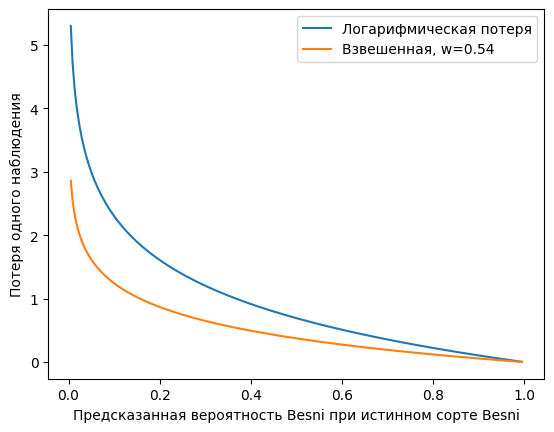

,ММП,Взвешенная M-оценка
Средняя потеря,0.358486,0.358503
Взвешенная средняя потеря,0.357447,0.357431


In [12]:
p = np.linspace(0.005, 0.995, 250)
plt.plot(p, -np.log(p), label="Логарифмическая потеря")
plt.plot(p, -weights.min()*np.log(p), label=f"Взвешенная, w={weights.min():.2f}")
plt.xlabel("Предсказанная вероятность Besni при истинном сорте Besni")
plt.ylabel("Потеря одного наблюдения")
plt.legend()
plt.show()

scores = {}
for name, b in [("ММП", mle), ("Взвешенная M-оценка", weighted)]:
    eta = Z @ b
    losses = np.logaddexp(0, eta) - target*eta
    scores[name] = [losses.mean(), np.average(losses, weights=weights)]
display(pd.DataFrame(scores, index=["Средняя потеря", "Взвешенная средняя потеря"]))

Для ягоды сорта Besni потеря растёт, когда модель приписывает этому сорту всё меньшую вероятность. Уменьшение веса снижает вклад такой ошибки.

В первой строке таблицы все ягоды имеют одинаковый вес. Средняя потеря немного меньше у классической оценки (0,358486 против 0,358503). Во второй строке учтены веса ягод, и меньшую потерю даёт взвешенная оценка (0,357431 против 0,357447). В обеих строках разница меньше 0,00002. На этих 900 ягодах взвешивание почти не изменило средние потери.